# Hafta 5 — Rastgele Orman, XGBoost ve Ablasyon

Ağaç modelleri için ön işleme `src/preprocessing.py`, modeller `src/modeling.py`, karşılaştırma tablosu `src/evaluate.py` içindedir. Rapordaki sayıların kaynağı `notebooks/build_model_karsilastirma.py` ile üretilen `hafta5_ozet.json` dosyasıdır. Test seti ayrılır ama hiçbir hücrede kullanılmaz.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw
from src.evaluate import build_comparison_table, summarize_cv
from src.model_plots import plot_model_comparison, plot_pr_curves_overlay
from src.modeling import MODEL_LABELS, build_logistic_regression, build_random_forest, build_xgboost, cross_validate_model, make_cv
from src.preprocessing import build_tree_feature_pipeline, split_train_test

split = split_train_test(load_raw())
print('eğitim:', split.X_train.shape, 'test:', split.X_test.shape)

eğitim: (36168, 15) test: (9043, 15)


## 1. Ağaç modelleri için ön işleme çıktısı

In [2]:
trees = build_tree_feature_pipeline().fit(split.X_train)
names = trees.named_steps['preprocess'].get_feature_names_out()
print(len(names), 'özellik')
list(names)

48 özellik


['numeric__age',
 'numeric__balance',
 'numeric__day',
 'numeric__campaign',
 'numeric__pdays',
 'numeric__previous',
 'binary__default',
 'binary__housing',
 'binary__loan',
 'flag__was_contacted_before',
 'nominal__job_admin.',
 'nominal__job_blue-collar',
 'nominal__job_entrepreneur',
 'nominal__job_housemaid',
 'nominal__job_management',
 'nominal__job_retired',
 'nominal__job_self-employed',
 'nominal__job_services',
 'nominal__job_student',
 'nominal__job_technician',
 'nominal__job_unemployed',
 'nominal__job_unknown',
 'nominal__marital_divorced',
 'nominal__marital_married',
 'nominal__marital_single',
 'nominal__education_primary',
 'nominal__education_secondary',
 'nominal__education_tertiary',
 'nominal__education_unknown',
 'nominal__contact_cellular',
 'nominal__contact_telephone',
 'nominal__contact_unknown',
 'nominal__month_apr',
 'nominal__month_aug',
 'nominal__month_dec',
 'nominal__month_feb',
 'nominal__month_jan',
 'nominal__month_jul',
 'nominal__month_jun',
 'n

## 2. Üç model, aynı 5 katlı katmanlı CV

In [3]:
cv = make_cv()
builders = {'logistic_regression': build_logistic_regression, 'random_forest': build_random_forest, 'xgboost': build_xgboost}
results = {name: cross_validate_model(build(), split.X_train, split.y_train, cv) for name, build in builders.items()}
summaries = {MODEL_LABELS[name]: summarize_cv(result.fold_metrics) for name, result in results.items()}
build_comparison_table(summaries, ['pr_auc', 'roc_auc', 'recall', 'precision', 'f1']).round(4)

pr_auc         roc_auc          recall         precision  \
                      mean     std    mean     std    mean     std      mean   
Lojistik Regresyon  0.4088  0.0107  0.7698  0.0044  0.1865  0.0113    0.6330   
Rastgele Orman      0.4472  0.0186  0.7961  0.0059  0.1832  0.0103    0.6846   
XGBoost             0.4532  0.0135  0.8011  0.0021  0.2392  0.0175    0.6329   

                                f1          
                       std    mean     std  
Lojistik Regresyon  0.0146  0.2879  0.0132  
Rastgele Orman      0.0133  0.2889  0.0134  
XGBoost             0.0308  0.3471  0.0225

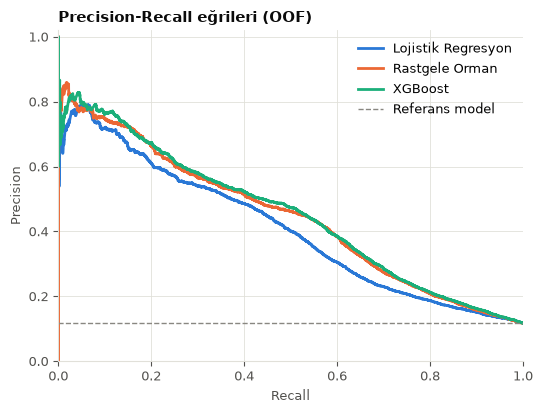

In [4]:
oof = {name: result.oof_proba for name, result in results.items()}
plot_pr_curves_overlay(split.y_train, oof, MODEL_LABELS);